# E130: does teacher training's placement protect every copy it makes?

**The answer.** The protection is not constant, but where it fails is not settled. The copy of a rank-8 LoRA trained for 2,400 steps cuts its excess to about a quarter on all four blocks of 128 rows read. The copy of the full Adam fine-tune stopped after 20 steps does not hold steady. On the first 256 rows its placement added half again to the excess; on a second 256 rows it cut the excess only to about four fifths. So placement adding excess is not established on that copy.

Report: `reports/analyses/2026-11-07_analysis_e130-copy-protection.md`. Jobs 55000 and 55031 (Amendment 1), MATS `debug` L40, $0, every control reproduced exactly. Provisional: no independent check.


## What we were trying to test

Each matrix of the decomposition is $W = UV^\top + \Delta$, with Γ and Δ frozen. *Teacher training* copies a fine-tuned model into the decomposition by training only the alive subcomponents' vectors $U, V$ on the KL divergence from the fine-tuned model. *The check* is VPD's mask adversary on Pile rows 0-255, one 20-step adversary per block of 128 rows. A state's **ratio** is its adversarial KL over W₀'s: 1 means as hard to break as the released decomposition, and E39's fail line is 1.61. *Do-nothing* leaves the fine-tune's own change in Δ.

A copy's weight change is $S_c = U'V'^\top - UV^\top$. We read it in two places at the same weights. **As placed**, it rides the alive subcomponents, where teacher training put it. **In Δ**, the subcomponents stay at the released $U, V$ and $S_c$ sits in Δ. The multiplier $m = (\text{placed} - 1)/(\text{in Δ} - 1)$ compares the two excesses: under 1 the placement protects, over 1 it exposes.

E127 read two lowercase copies this way and found $m$ of 0.36 and 0.24: teacher training's placement divided the excess by three to four. Here two more copies by the same recipe are read:

- **the step-20 Adam copy**, of the full Adam fine-tune stopped at step 20, with the LoRA's damage to plain text;
- **the step-2,400 LoRA copy**, of a rank-8 LoRA trained on to step 2,400, with the full Adam fine-tune's damage.

If the division belongs to the recipe, both should read $m$ at 0.5 or under.

## What we expected, and why

Fable leaned the other way, at 0.55: the step-20 Adam copy already looked unprotected, its placed excess 76% of its do-nothing's. If its change in Δ read like earlier copies', at most 0.81 of do-nothing's excess, it would read 2.7 to 2.9 there and $m$ near 1. The LoRA copy was expected to stay protected, $m$ 0.25 to 0.4.


## What we observed

### Does teacher training's placement shrink each copy's excess?


copy                              placed  in Delta      m
full Adam, step 300                1.913     3.526   0.36
rank-8 LoRA, step 300              1.326     2.336   0.24
full Adam, step 20 (new)           2.842     2.165   1.58
rank-8 LoRA, step 2,400 (new)      1.534     3.167   0.25


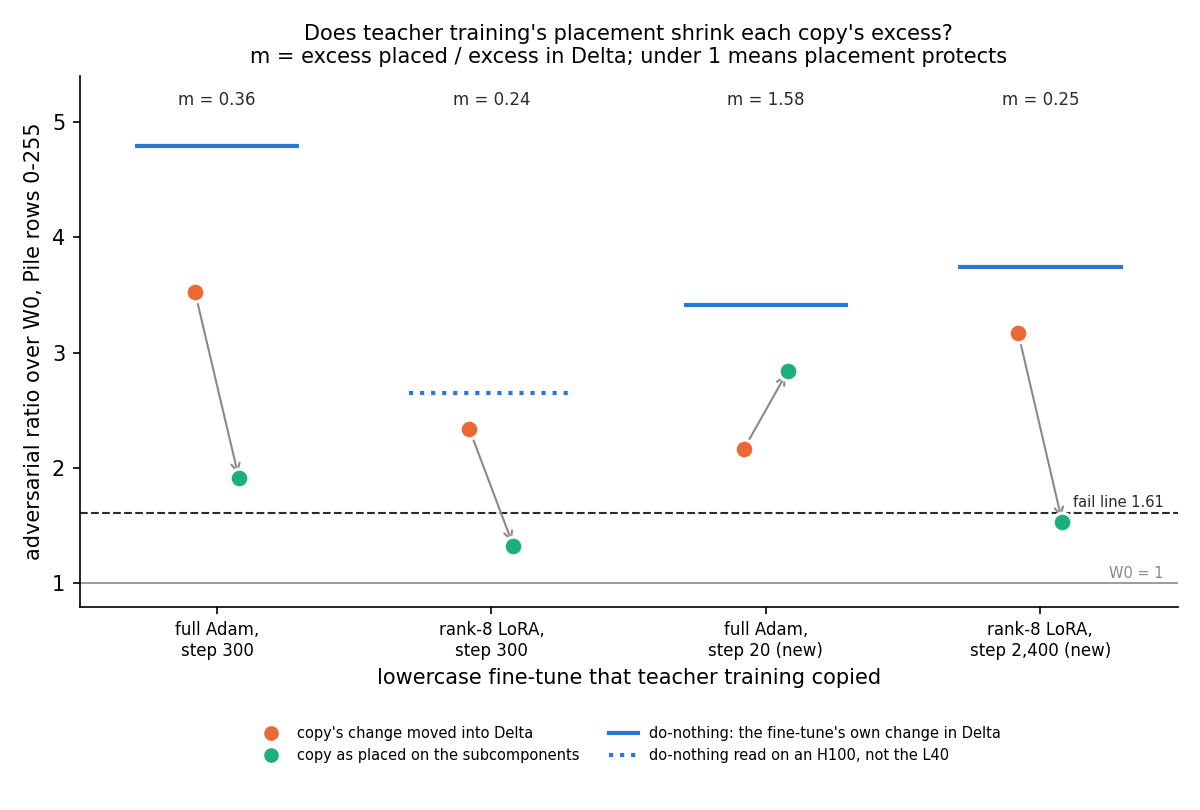

In [1]:
import json
from pathlib import Path

from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
out = json.loads((ROOT / "experiments/copy_protection/results/copy_protection.json").read_text())
a2 = json.loads((ROOT / "experiments/ls_start_faith/results/ls_start_faith_amend2.json").read_text())["score"]["ratio"]
r = out["score"]["ratio"]
rows = [("full Adam, step 300", a2["std_copy"], a2["std_copy|delta"]),
        ("rank-8 LoRA, step 300", a2["lora_copy"], a2["lora_copy|delta"]),
        ("full Adam, step 20 (new)", r["c1"], r["c1|delta"]),
        ("rank-8 LoRA, step 2,400 (new)", r["c2"], r["c2|delta"])]
print(f"{'copy':32s}{'placed':>8s}{'in Delta':>10s}{'m':>7s}")
for name, placed, delta in rows:
    print(f"{name:32s}{placed:8.3f}{delta:10.3f}{(placed - 1) / (delta - 1):7.2f}")
display(Image(filename=str(ROOT / "experiments/copy_protection/figures/placement.png")))


**Reading it.** Not for every copy: on the step-20 Adam copy the placement makes the excess larger. Each orange point is a copy's change in Δ, each green point the same change as placed. On three copies the arrow points down, to a quarter or a third of the in-Δ excess. On the step-20 Adam copy it points up: 2.17 in Δ becomes 2.84 placed, so $m$ is 1.58. All four in-Δ reads sit under their own do-nothing, the blue bar, and the step-20 copy's furthest under it. So that copy carries a change that would read fairly well in Δ, and teacher training placed it where the adversary finds more. One seed and one row set per copy; the reversal comes from one of the two 128-row blocks, where the placed copy reads 4.35 and its change in Δ 2.91.


## Amendment 1: does the step-20 copy's reversal hold on other rows?

The reversal above rests on one block of 128 rows. Amendment 1 repeated the reads on Pile rows 256-511, two more blocks of 128 disjoint from the first, with the same code, card type, adversary seed and rule. W₀ and both placed copies reproduced their stored readings on these rows exactly. The filed outcome: if the step-20 copy reads "no protection" over both new blocks, $m$ at 0.8 or over, the reversal holds; otherwise it does not replicate. The filing called the test weak: the copy's placed excess here is only about two floors, so one floor of noise on each read moves $m$ between 0.31 and 1.89. The lean was even.


copy                        rows 256-383  rows 384-511  rows 256-511
full Adam, step 20                  0.60          0.97          0.78
rank-8 LoRA, step 2,400             0.27          0.28          0.28
outcome: reversal does not replicate


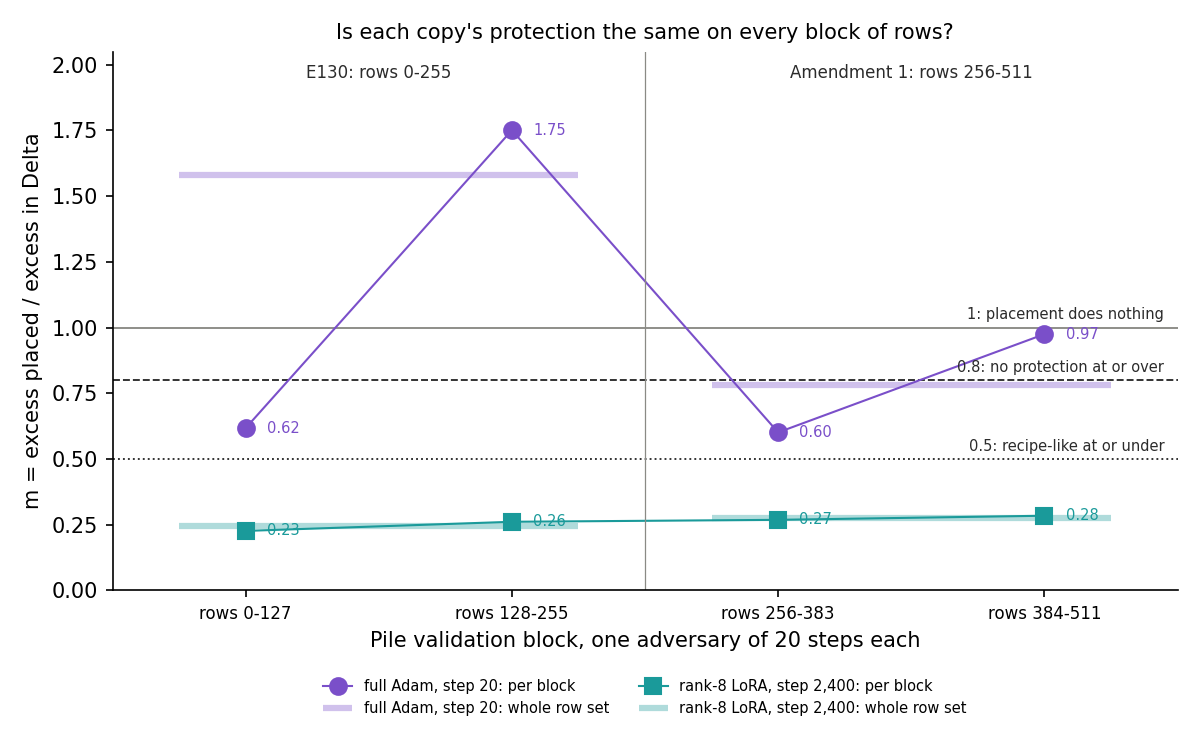

In [2]:
a1 = json.loads((ROOT / "experiments/copy_protection/results/copy_protection_amend1.json").read_text())["score"]
print(f"{'copy':26s}{'rows 256-383':>14s}{'rows 384-511':>14s}{'rows 256-511':>14s}")
for copy, name in (("c1", "full Adam, step 20"), ("c2", "rank-8 LoRA, step 2,400")):
    ms = [a1[k]["copies"][copy]["m"] for k in ("block rows 256-383", "block rows 384-511", "overall")]
    print(f"{name:26s}" + "".join(f"{m:14.2f}" for m in ms))
print("outcome:", a1["outcome"])
display(Image(filename=str(ROOT / "experiments/copy_protection/figures/amend1_blocks.png")))


**Reading it.** The reversal does not replicate: on rows 256-511 the step-20 copy's placement cuts its excess partly, to $m$ 0.78, just under the 0.8 line for no protection. Over four blocks that copy reads 0.62, 1.75, 0.60 and 0.97, while the LoRA copy reads 0.23 to 0.28 on every block. So the LoRA copy's protection is stable across rows and the step-20 copy's is not: it ranges from partial to none, and adds excess on one block only. The miss of the 0.8 line by 0.02 sits far inside the read's noise, so this says "not established", not "protects". On these rows the step-20 fine-tune itself passes the check, its do-nothing at 1.37, and the copy's change in Δ reads above it, at 1.57.

**What it changes.** The headline "function-dependent" stands only as "not constant": the LoRA copies stay protected on every block read, and the step-20 copy's placement adding excess is no longer established. Where teacher training's protection fails is not settled.


## What we learned

Teacher training's placement is not a constant of the recipe. Across the four lowercase copies trained from W₀'s start, $m$ on rows 0-255 runs from 0.24 to 1.58, and the 1.58 fell to 0.78 on a second row set. As description only, one seed each: the two copies of rank-8 LoRA fine-tunes read 0.24 and 0.25, the two copies of full Adam fine-tunes 0.36 and 1.58. Damage to plain text does not order them. Teacher training's loss has no mask or adversary term, so nothing asks for protection, and here it did not always come. For `GOALS.md`, a carrier for broad updates needs a placement that protects by design.

## How compelling is the evidence

One adversary seed and one card; two row sets for the two new copies, one for the earlier two. Every control reproduced to the last digit. The step-20 copy's verdict sits 5.4 floors from its edge, but rests on one block of 128 rows. The LoRA copy's placed excess is only 2.6 floors, so its $m$ is coarse, 0.14 to 0.38 within a floor. The two new copies sit at the same input-weighted cosine to their fine-tunes, 0.58 and 0.59, yet are placed with opposite effect.

## Surprises

Placement made one copy worse: we expected $m$ near 1 for the step-20 Adam copy and read 1.58. Its in-Δ ratio, 2.17, fell under the lean band of 2.7 to 2.9. The LoRA copy's values sat just outside their bands, a narrow miss.

## What next

- The step-20 copy on Pile rows 256-511: done as Amendment 1, below. The reversal did not replicate.
- Where each of the four copies' changes sits against Γ's causal importances: the two new copies give a contrast to explain.
- Teacher training with a masked or adversarial term, the synthesis' run for the broad failure.

## Scorecard

| id | rule | read | verdict |
|---|---|---|---|
| C1, C2 | W₀ and both placed copies within 1e-3 of stored | exact | held |
| R2 c1 | m ≤ 0.5 recipe-like, ≥ 0.8 no protection | 1.58 | no protection, as leaned |
| R2 c2 | same | 0.25 | recipe-like, as leaned |
| R3 | any no protection → function-dependent | | function-dependent, as leaned |
| lean c1 in Δ | 2.7-2.9 | 2.17 | missed low |
| A1 outcome, rows 256-511 | c1 m ≥ 0.8 → reversal holds | 0.78 | partial: does not replicate |
| A1 c2, rows 256-511 | report only | 0.28 | recipe-like |

**Not run:** adversary seeds 1-2 on any rows; a floor on rows 256-511; E127's two copies on rows 256-511; the causal-importance placement read; cosines of E127's two copies; the LoRA's do-nothing on the L40; more copies or tasks; an independent check.
